# Three group analysis - Tace First, Systemic First, Simultaneous

## Load data

In [139]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import subprocess

import warnings
from lifelines.exceptions import StatisticalWarning
warnings.filterwarnings("ignore", category=StatisticalWarning)


df = pd.read_csv('analysis_ready.csv')
df.shape

(1858, 357)

In [140]:
covariates = [
    'AGE', 'SEX', 'RACE',
    'INSURANCE_STATUS',
    'Charlson_Deyo_Score', 'HISTOLOGY', 'COMBINED_STAGE_GROUP',
    'YEAR_OF_DIAGNOSIS', 'Surgery', 'Radiation_Therapy'
]
df.shape

(1858, 357)

In [141]:
df = df[df['COMBINED_STAGE_GROUP'].isin([3, 4])]
df['sequence_group'].value_counts()

sequence_group
0    930
2    291
1    205
Name: count, dtype: int64

## Distribution of surgery status across stages

<Figure size 1000x600 with 0 Axes>

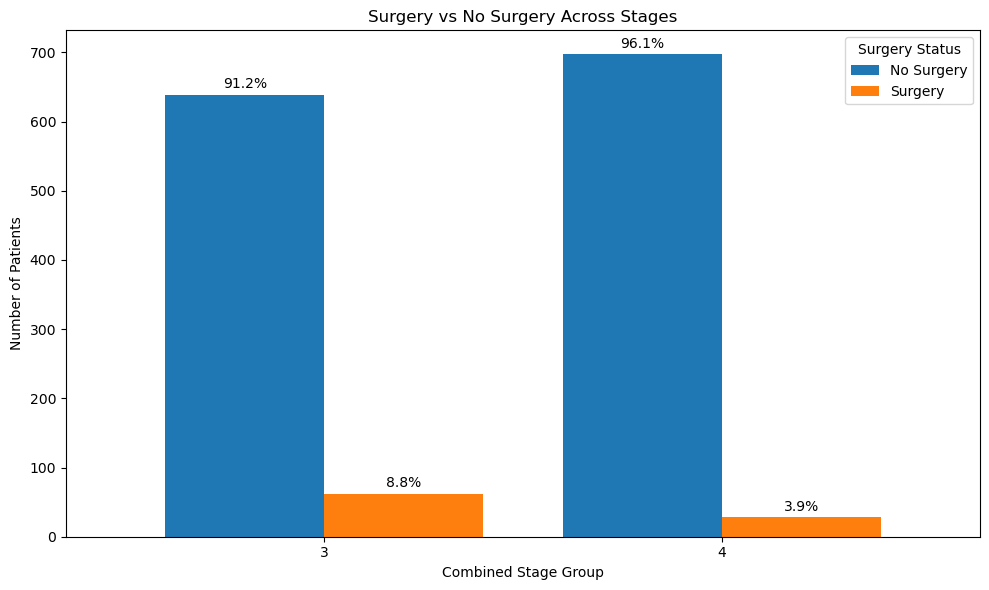

In [142]:
plt.figure(figsize=(10, 6))
stage_surgery_counts = df.groupby(['COMBINED_STAGE_GROUP', 'Surgery']).size().unstack()

# Calculate percentages
stage_surgery_percentages = stage_surgery_counts.div(stage_surgery_counts.sum(axis=1), axis=0) * 100

# Plot the bar chart
ax = stage_surgery_counts.plot(
    kind='bar',
    stacked=False,
    figsize=(10, 6),
    color=['#1f77b4', '#ff7f0e'],  # Colors for no surgery and surgery
    width=0.8
)

# Annotate percentages
for i, stage in enumerate(stage_surgery_counts.index):
    for j, surgery_status in enumerate(stage_surgery_counts.columns):
        count = stage_surgery_counts.loc[stage, surgery_status]
        percentage = stage_surgery_percentages.loc[stage, surgery_status]
        ax.text(
            i + (j - 0.5) * 0.4,  # Adjust x position for each bar
            count + 5,  # Adjust y position slightly above the bar
            f'{percentage:.1f}%',
            ha='center',
            va='bottom',
            fontsize=10
        )

plt.title('Surgery vs No Surgery Across Stages')
plt.xlabel('Combined Stage Group')
plt.ylabel('Number of Patients')
plt.legend(['No Surgery', 'Surgery'], title='Surgery Status')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Distribution of sequence group across stages

<Figure size 1000x600 with 0 Axes>

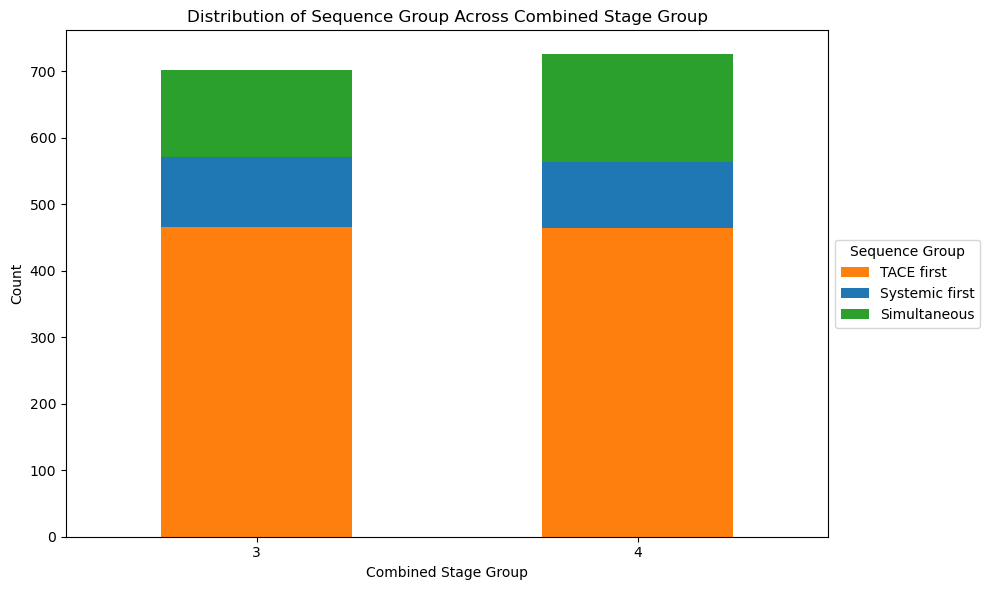

In [143]:
plt.figure(figsize=(10, 6))
ax = df.groupby(['COMBINED_STAGE_GROUP', 'sequence_group']).size().unstack().plot(
    kind='bar', 
    stacked=True, 
    figsize=(10, 6), 
    color=['#ff7f0e', '#1f77b4', '#2ca02c']  # Switch colors for TACE first and Systemic first
)

plt.title('Distribution of Sequence Group Across Combined Stage Group')
plt.xlabel('Combined Stage Group')
plt.ylabel('Count')

# Move the legend outside the plot
plt.legend(
    ['TACE first', 'Systemic first', 'Simultaneous'], 
    title='Sequence Group', 
    loc='center left', 
    bbox_to_anchor=(1, 0.5)  # Place legend outside the plot
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=0)  # Set x-ticks rotation to 0 degrees
plt.rcParams['pdf.fonttype'] = 42
#plt.savefig('stage_distribution.pdf', format='pdf', bbox_inches='tight')
plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

## Survival functions

### Functions for 3-group comparison

In [144]:
def plot_survival_3g(
    ref_group,
    kmf_dict,
    hr_dict,
    ci_low_dict,
    ci_high_dict,
    p_dict,
    llp,
    surv_text,
    risk_dict,
    time_grid,
    file_name=None
):
    from matplotlib import gridspec

    labels = list(kmf_dict.keys())
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

    # --- Figure & subplots ---
    fig = plt.figure(figsize=(9,7))
    gs = gridspec.GridSpec(2,1,
                           height_ratios=[4, 1.5],
                           hspace=0.2)
    ax_km = fig.add_subplot(gs[0])
    ax_table = fig.add_subplot(gs[1], sharex=ax_km)
    ax_table.axis('off')

    # --- KM curves ---
    for lbl, col in zip(labels, colors):
        kmf_dict[lbl].plot(ax=ax_km, ci_show=False, color=col, linewidth=3)

    # --- Ensure x-axis labels on KM ---
    ax_km.set_xlabel('Months', fontsize=18, fontweight='bold')
    ax_km.set_xticks(time_grid)
    ax_km.tick_params(axis='x', labelbottom=True, bottom=True, labelsize=12)
    ax_km.minorticks_off()

    # --- Add legend ---
    ax_km.legend(loc='lower left', frameon = False, fontsize=16)  # Change 'upper right' to desired location

    # --- Formatting KM axis ---
    ax_km.set_title(ref_group + ' as reference', fontsize=18, fontweight='bold')
    ax_km.set_ylabel('Overall Survival Rate (%)', fontsize=18, fontweight='bold')
    ax_km.spines['top'].set_visible(False)
    ax_km.spines['right'].set_visible(False)
    ax_km.set_xlim(0, max(time_grid))

    # --- Manual risk table via text and dashes ---
    for i, lbl in enumerate(labels):
        y_frac = 0.75 - i * 0.15
        delta = (time_grid[1] - time_grid[0]) * 0.4  
        x0 = time_grid[0] - delta
        x1 = x0 + (delta * 0.5)

        ax_table.plot(
            [x0, x1],
            [y_frac, y_frac],
            color=colors[i],
            linewidth=3,
            transform=ax_table.get_xaxis_transform(),
            solid_capstyle='butt',
            clip_on=False
        )
        for t, n in zip(time_grid, risk_dict[lbl][:len(time_grid)]):
            ax_table.text(
                t, y_frac, str(n),
                color=colors[i], fontsize=18,
                va='center', ha='center',
                transform=ax_table.get_xaxis_transform(),
                clip_on=False
            )
    ax_table.text(
        -0.1, 0.9,
        'Number at Risk (n)', fontsize=12,
        ha='left', transform=ax_table.transAxes
    )

    ax_table.xaxis.set_visible(False)
    ax_table.yaxis.set_visible(False)

    # --- Final layout ---
    plt.subplots_adjust(top=0.92, bottom=0.07)
    plt.text(
        0.5, 0.3, 'Months',
        fontsize=16, fontweight='bold', ha='center', transform=fig.transFigure
    )
    plt.rcParams['pdf.fonttype'] = 42
    if file_name:
        plt.savefig(f"{file_name}.pdf", format='pdf', bbox_inches='tight')
    plt.show()

def survival_analysis_3g(df, time_grid, group_col, ref_group, llp, file_name=None):
    """
    Perform unweighted CoxPH and KM for three-level sequence_group.

    df must have columns: time, event, sequence_group (0,1,2).
    Returns nothing but prints 3-yr/5-yr surv and calls plot_survival.
    """
    # One-hot encode sequence_group for CoxPH (0 as reference)
    dummies = pd.get_dummies(df[group_col], prefix='seq', drop_first=True)
    cox_df = pd.concat([df[['time', 'event']], dummies], axis=1)

    cph = CoxPHFitter()
    cph.fit(cox_df, duration_col='time', event_col='event')
    summary = cph.summary
    cph.print_summary()

    # Extract stats
    hr_dict = {}
    ci_low_dict = {}
    ci_high_dict = {}
    p_dict = {}
    if ref_group == 'TACE':
        label_map = {'seq_1': 'Systemic First', 'seq_2': 'Simultaneous'}
    elif ref_group == 'Systemic':
        label_map = {'seq_1': 'TACE First', 'seq_2': 'Simultaneous'}
    elif ref_group == 'Simultaneous':
        label_map = {'seq_1': 'TACE First', 'seq_2': 'Systemic First'}
    else:
        raise ValueError(f"Unknown reference group: {ref_group}")
    # Reference group
    hr_dict[ref_group] = 1.0
    ci_low_dict[ref_group] = None
    ci_high_dict[ref_group] = None
    p_dict[ref_group] = None
    for idx, row in summary.iterrows():
        lbl = label_map.get(idx, idx)
        hr_dict[lbl] = row['exp(coef)']
        ci_low_dict[lbl] = row['exp(coef) lower 95%']
        ci_high_dict[lbl] = row['exp(coef) upper 95%']
        p_dict[lbl] = row['p'].round(3)

    # KM fits
    kmf_dict = {}
    surv_text = {}
    risk_dict = {}

    if ref_group == 'TACE':
        label_seq = ['TACE First','Systemic First','Simultaneous']
    elif ref_group == 'Systemic':
        label_seq = ['Systemic First','TACE First','Simultaneous']
    elif ref_group == 'Simultaneous':
        label_seq = ['Simultaneous','TACE First','Systemic First']
    else:
        raise ValueError(f"Unknown reference group: {ref_group}")

    for val, lbl in zip([0,1,2], label_seq):
        kmf = KaplanMeierFitter(label=lbl)
        mask = df[group_col]==val
        kmf.fit(df.loc[mask,'time'], event_observed=df.loc[mask,'event'])
        kmf_dict[lbl] = kmf
        # 3yr & 5yr surv
        surv_text[lbl] = {t: f"{kmf.predict(t):.1%}" for t in [36, 60]}
        # risk counts
        counts = []
        group = df[df[group_col]==val]
        for t in time_grid:
            counts.append(group[group['time']>=t].shape[0])
        risk_dict[lbl] = counts

        # print survival at t
        for t in [36, 60]:
            lower, upper = None, None
            # CI from kmf.confidence_interval_
            ci = kmf.confidence_interval_
            if not ci.empty:
                nearest = ci.index.get_indexer([t], method='nearest')[0]
                lower = ci.iloc[nearest, 0]
                upper = ci.iloc[nearest, 1]
            surv = kmf.predict(t)
            if lower is None or upper is None:
                print(f"{lbl} at {t} mo: {surv:.1%} (CI not estimable)")
            else:
                print(f"{lbl} at {t} mo: {surv:.1%} ({lower:.1%}-{upper:.1%})")

    if file_name:
        plot_survival_3g(ref_group, kmf_dict, hr_dict, ci_low_dict, ci_high_dict, p_dict, llp,
                  surv_text, risk_dict, time_grid, file_name=file_name)
    else:
        plot_survival_3g(ref_group, kmf_dict, hr_dict, ci_low_dict, ci_high_dict, p_dict, llp,
                  surv_text, risk_dict, time_grid)
    return

### Functions for pair-wise comparison

In [145]:
def weighted_risk_counts(df, time_points, group_value):
    risk_counts = []
    group = df[df['sequence_group'] == group_value]
    for t in time_points:
        still_at_risk = group[group['time'] >= t]['iptw_weight'].sum()
        risk_counts.append(int(round(still_at_risk)))
    return risk_counts

def risk_counts(df, time_points, group_value):
    risk_counts = []
    group = df[df['sequence_group'] == group_value]
    for t in time_points:
        still_at_risk = group[group['time'] >= t].shape[0]
        risk_counts.append(still_at_risk)
    return risk_counts

def survival_with_ci(kmf, time):
    surv = kmf.predict(time)
    
    closest_idx = kmf.confidence_interval_.index.get_indexer([time], method='nearest')[0]
    ci = kmf.confidence_interval_.iloc[closest_idx]

    lower = ci.iloc[0]
    upper = ci.iloc[1]

    # sanity check for CI
    if (upper == 1.0 and lower == 1.0) or (upper == 0.0 and lower == 0.0):
        return surv, None, None  # invalid or non-estimable CI

    return surv, lower, upper

def plot_survival(groups, colors, kmf_0, kmf_1, hr, ci_low, ci_high, p_val, surv_text, risk_0, risk_1, time_grid, weighted=False, file_name=None):
    fig = plt.figure(figsize=(9, 7))
    gs = gridspec.GridSpec(2, 1, height_ratios=[4, 0.75], hspace=0.05)

    # KM Plot
    ax_km = plt.subplot(gs[0])
    kmf_0.plot(ax=ax_km, ci_show=True, color=colors[0], linewidth=3)
    kmf_1.plot(ax=ax_km, ci_show=True, color=colors[1], linewidth=3)

    # Survival annotation
    for x in [36, 60]:
        ax_km.text(x, kmf_1.predict(x)+0.075, surv_text[groups[1]][x],
                color=colors[1], fontsize=20, fontweight='bold', ha='center')
        ax_km.text(x, kmf_0.predict(x)-0.095, surv_text[groups[0]][x],
                color=colors[0], fontsize=20, fontweight='bold', ha='center')

    # Legend with colored lines
    custom_lines = [
        Line2D([0], [0], color=colors[0], lw=3),
        Line2D([0], [0], color=colors[1], lw=3)
    ]
    legend_labels = groups
    ax_km.legend(custom_lines, legend_labels,
                loc='lower left', frameon=False, fontsize=20)

    #Add HR and p-value
    hr_text = f"HR = {hr:.2f}\n(95% CI = {ci_low:.2f} – {ci_high:.2f})\n\nlogrank p={p_val}"
    ax_km.text(0.67, 0.75, hr_text, transform=ax_km.transAxes,
            fontsize=14, va='bottom', ha='left')

    # Format axes
    ax_km.set_title("IPTW-Weighted" if weighted else "Unweighted", fontsize=20, fontweight='bold')
    ax_km.set_ylabel("Overall Survival Rate (%)", fontsize=20, fontweight='bold')
    ax_km.set_xlabel("Months", fontsize=20, fontweight='bold')
    ax_km.set_xlim(0, 72)
    ax_km.set_xticks(time_grid)
    ax_km.tick_params(labelsize=12)

    # Remove top/right borders
    ax_km.spines["top"].set_visible(False)
    ax_km.spines["right"].set_visible(False)

    # Risk Table
    ax_table = plt.subplot(gs[1])
    ax_table.axis("off")

    # Only show counts, no month header row
    table_data = [
        [""] + [str(n) for n in risk_0[:len(time_grid)]],
        [""] + [str(n) for n in risk_1[:len(time_grid)]],
    ]

    # Create table
    risk_table = ax_table.table(
        cellText=table_data,
        cellLoc='center',
        loc='center',
        edges='open',
        bbox=[-0.245, -0.4, 1.325, 0.6],  # Adjust x, y, width, height

    )
    risk_table.auto_set_font_size(False)
    risk_table.set_fontsize(20)
    risk_table.scale(1.2, 1.3)

    # Style counts and remove lines
    for row_idx, color in enumerate([colors[0], colors[1]]):
        for col_idx in range(len(time_grid) + 1):
            cell = risk_table[(row_idx, col_idx)]
            cell.set_text_props(color=color)
            cell.set_linewidth(0)

    # Colored bars for group labels (aligned manually)
    ax_table.text(0, 0.40, "Weighted No. at Risk" if weighted else "Number at Risk", fontsize=12, transform=ax_table.transAxes, ha='center')
    ax_table.plot([-0.075, -0.05], [0.05, 0.05], color=colors[0], lw=4, transform=ax_table.transAxes, clip_on=False)
    ax_table.plot([-0.075, -0.05], [-0.25, -0.25], color=colors[1], lw=4, transform=ax_table.transAxes, clip_on=False)

    # Final spacing
    plt.subplots_adjust(top=0.93, bottom=0.07)
    plt.rcParams['pdf.fonttype'] = 42
    if file_name:
        plt.savefig(f"{file_name}.pdf", format='pdf', bbox_inches='tight')
    plt.show()

def survival_analysis(df, time_grid, groups, colors, strata = None, weight_col=None, file_name=None):
    cph = CoxPHFitter()
    
    if weight_col:
        cph.fit(df[['time', 'event', 'sequence_group', 'iptw_weight']], duration_col='time', event_col='event', weights_col='iptw_weight')
    elif strata:
        cph.fit(df[['time', 'event', 'sequence_group', strata]], duration_col='time', event_col='event', strata=[strata])
    else:
        cph.fit(df[['time', 'event', 'sequence_group']], duration_col='time', event_col='event')
        
    summary_df = cph.summary
    cph.print_summary()
    #p_val = summary_df.loc['sequence_group', 'p'].round(4)
    hr = summary_df.loc['sequence_group', 'exp(coef)']
    ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
    ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']

    if strata:
        tmp = "tmp_matched_for_survdiff.csv"
        df[['time','event','sequence_group', strata]].to_csv(tmp, index=False)

        r_cmd = (
            f"library(survival); "
            f"df <- read.csv('{tmp}'); "
            f"res <- survdiff(Surv(time,event) ~ sequence_group + strata({strata}), data=df); "
            f"cat(res$chisq, '\\n', pchisq(res$chisq, df=1, lower.tail=FALSE), '\\n')"
        )

        proc = subprocess.run(["Rscript", "-e", r_cmd], capture_output=True, text=True)
        if proc.returncode != 0:
            raise RuntimeError(f"Rscript failed: {proc.stderr.strip()}")

        out_lines = [ln.strip() for ln in proc.stdout.strip().splitlines() if ln.strip()]
        if len(out_lines) >= 2:
            p_val = round(float(out_lines[1]), 4)
        else:
            raise RuntimeError(f"Unexpected R output: {proc.stdout!r}")

    else:
        results = logrank_test(
            df[df['sequence_group'] == 0]['time'],
            df[df['sequence_group'] == 1]['time'],
            event_observed_A=df[df['sequence_group'] == 0]['event'],
            event_observed_B=df[df['sequence_group'] == 1]['event'],
            weights_A=df[df['sequence_group'] == 0][weight_col] if weight_col else None,
            weights_B=df[df['sequence_group'] == 1][weight_col] if weight_col else None
        )
        p_val = results.p_value.round(4)
    
    # KM
    mask_0 = df['sequence_group'] == 0
    mask_1 = df['sequence_group'] == 1
    
    kmf_0 = KaplanMeierFitter()
    kmf_1 = KaplanMeierFitter()
    
    kmf_0.fit(
        durations=df.loc[mask_0, 'time'],
        event_observed=df.loc[mask_0, 'event'],
        weights=df.loc[mask_0, 'iptw_weight'] if weight_col else None,
        label=groups[0]
    )
    
    kmf_1.fit(
        durations=df.loc[mask_1, 'time'],
        event_observed=df.loc[mask_1, 'event'],
        weights=df.loc[mask_1, 'iptw_weight'] if weight_col else None,
        label= groups[1]
    )
    
    # Number at risk
    risk_0 = weighted_risk_counts(df, time_grid, 0) if weight_col else risk_counts(df, time_grid, 0)
    risk_1 = weighted_risk_counts(df, time_grid, 1) if weight_col else risk_counts(df, time_grid, 1)
    
    # 3 & 5 year survival
    for t in [36, 60]:
        surv_1, low_1, high_1 = survival_with_ci(kmf_1, t)
        surv_0, low_0, high_0 = survival_with_ci(kmf_0, t)
    
        print(f"\nTime: {t} months")
        if low_0 is None or high_0 is None:
            print(f"{groups[0]}: {surv_0:.1%} (CI not estimable)")
        else:
            print(f"{groups[0]}: {surv_0:.1%} ({low_0:.1%} – {high_0:.1%})")
        if low_1 is None or high_1 is None:
            print(f"{groups[1]}: {surv_1:.1%} (CI not estimable)")
        else:
            print(f"{groups[1]}: {surv_1:.1%} ({low_1:.1%} – {high_1:.1%})")
        
    # Plot
    surv_text = {
        groups[1]: {
            36: f"{kmf_1.predict(36):.1%}",
            60: f"{kmf_1.predict(60):.1%}"
        },
        groups[0]: {
            36: f"{kmf_0.predict(36):.1%}",
            60: f"{kmf_0.predict(60):.1%}"
        }
    }
    
    if file_name:
        plot_survival(
            groups,colors, kmf_0, kmf_1, hr, ci_low, ci_high, p_val,
            surv_text, risk_0, risk_1, time_grid, bool(weight_col), file_name
        )
    else:
        plot_survival(
            groups, colors, kmf_0, kmf_1, hr, ci_low, ci_high, p_val,
            surv_text, risk_0, risk_1, time_grid, bool(weight_col)
        )

### IPTW

In [146]:
def perform_iptw(df, covariates = covariates):
    df_encoded = pd.get_dummies(df[covariates], drop_first=True)
    X = df_encoded
    y = df['sequence_group']
    ps_model = LogisticRegression(max_iter=2000)
    ps_model.fit(X, y)
    df['ps'] = ps_model.predict_proba(X)[:, 1]
    df['iptw_weight'] = df.apply(
        lambda row: 1 / row['ps'] if row['sequence_group'] == 1 else 1 / (1 - row['ps']),
        axis=1
    )
    return df

def compute_asmd(df, covariate, treatment_col, weight_col=None):
    groups = df[treatment_col].unique()
    g1 = df[df[treatment_col] == groups[0]]
    g2 = df[df[treatment_col] == groups[1]]

    if weight_col is None:
        w1 = np.ones(len(g1))
        w2 = np.ones(len(g2))
    else:
        w1 = g1[weight_col].values
        w2 = g2[weight_col].values

    def weighted_mean_std(x, w):
        mean = np.average(x, weights=w)
        var = np.average((x - mean)**2, weights=w)
        return mean, np.sqrt(var)

    if df[covariate].dtype in [np.float64, np.int64]:
        m1, s1 = weighted_mean_std(g1[covariate], w1)
        m2, s2 = weighted_mean_std(g2[covariate], w2)
        pooled_sd = np.sqrt((s1**2 + s2**2)/2)
        asmd = abs(m1 - m2) / pooled_sd
    else:
        # Categorical variable: use dummy encoding
        dummies = pd.get_dummies(df[covariate], drop_first=False)
        asmd_list = []
        for level in dummies.columns:
            x1 = dummies.loc[g1.index, level]
            x2 = dummies.loc[g2.index, level]
            m1 = np.average(x1, weights=w1)
            m2 = np.average(x2, weights=w2)
            pooled = (m1*(1 - m1) + m2*(1 - m2)) / 2
            asmd = abs(m1 - m2) / np.sqrt(pooled) if pooled > 0 else 0
            asmd_list.append(asmd)
        asmd = np.mean(asmd_list)
    return asmd

def generate_iptw_plots(df, groups, file_name=None):
    # Create a figure with two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

    # Plot 1: Propensity Score Distribution Pre-weighting
    sns.histplot(
        data=df[df['sequence_group'] == 1],
        x='ps', bins=25, stat='density',
        color='skyblue', label=groups[1], element='step',
        ax=axes[0]
    )
    sns.histplot(
        data=df[df['sequence_group'] == 0],
        x='ps', bins=25, stat='density',
        color='salmon', label=groups[0], element='step',
        ax=axes[0]
    )
    axes[0].set_title("Propensity Score Distribution Pre-weighting")
    axes[0].set_xlabel("Propensity Score")
    axes[0].set_ylabel("Density")

    # Plot 2: Propensity Score Distribution After IPTW
    sns.histplot(
        data=df[df['sequence_group'] == 1],
        x='ps', weights='iptw_weight', bins=25, stat='density',
        color='skyblue', label=groups[1], element='step',
        ax=axes[1]
    )
    sns.histplot(
        data=df[df['sequence_group'] == 0],
        x='ps', weights='iptw_weight', bins=25, stat='density',
        color='salmon', label=groups[0], element='step',
        ax=axes[1]
    )
    axes[1].set_title("Propensity Score Distribution After IPTW")
    axes[1].set_xlabel("Propensity Score")

    # Add a single legend for both plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=2, title="Treatment Group")

    # Adjust layout
    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend
    if file_name:
        plt.savefig(f"{file_name}_ps.pdf", format = 'pdf', bbox_inches='tight')
    plt.show()

    asmd_unweighted = []
    asmd_weighted = []

    for covariate in covariates:
        try:
            a1 = compute_asmd(df, covariate, 'sequence_group', weight_col=None)
            a2 = compute_asmd(df, covariate, 'sequence_group', weight_col='iptw_weight')
        except Exception as e:
            print(f"Skipping {covariate}: {e}")
            continue
        asmd_unweighted.append(a1)
        asmd_weighted.append(a2)

    asmd_df = pd.DataFrame({
        'Covariate': covariates,
        'Unweighted': asmd_unweighted,
        'IPTW': asmd_weighted
    })
    asmd_df.sort_values(by='Unweighted', ascending=True, inplace=True)

    asmd_df_melted = asmd_df.melt(id_vars='Covariate', var_name='Method', value_name='ASMD')

    plt.figure(figsize=(10, 6))
    sns.pointplot(
        data=asmd_df_melted,
        x='ASMD',
        y='Covariate',
        hue='Method',
        dodge=True,  # Separate points for each method
        linestyle='none',  # Do not connect points with lines
        markers=["o", "s", "D"],  # Optional: Different markers for clarity
        palette="Set2"  # Optional: Custom color palette
    )
    plt.axvline(0.1, linestyle='--', color='orange', label='ASMD = 0.1 threshold')
    plt.xlabel("Absolute Standardized Mean Difference")
    plt.title("Covariate Balance: Unweighted vs IPTW")
    plt.legend(loc='upper right')
    plt.tight_layout()
    if file_name:
        plt.savefig(f"{file_name}_iptw.pdf", format = 'pdf', bbox_inches='tight')

    plt.show()

## 3-group comparisons

### TACE-ref

<lifelines.CoxPHFitter: fitted with 1426 total observations, 361 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1426
number of events observed = 1065
   partial log-likelihood = -6976.58
         time fit was run = 2025-09-29 22:39:47 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1     -0.19      0.83      0.09           -0.38           -0.01                0.69                0.99
seq_2      0.06      1.06      0.08           -0.10            0.21                0.91                1.23

           cmp to     z    p  -log2(p)
covariate                             
seq_1        0.00 -2.05 0.04      4.63
seq_2        0.00  0.74 0.46      1.11
---
Concordance = 0.53
Partial AIC = 13957.16
log-likelihood ratio test = 5.76 on 2 df
-log2(p) of ll-ratio test = 4.15

TACE First at 36 mo: 21.3% (18.4%-24.1%)
TACE First at 60 mo: 14.4% (11.6%-17.5%)
Systemic First at 36 mo: 28.9% (20.6%-35.2%)
Systemic First at 60 mo: 14.0% (5.9%-25.6%)
Simultaneous at 36 mo: 23.0% (17.7%-28.6%)
Simultaneous at 60 mo: 15.8% (10.0%-22.8%)


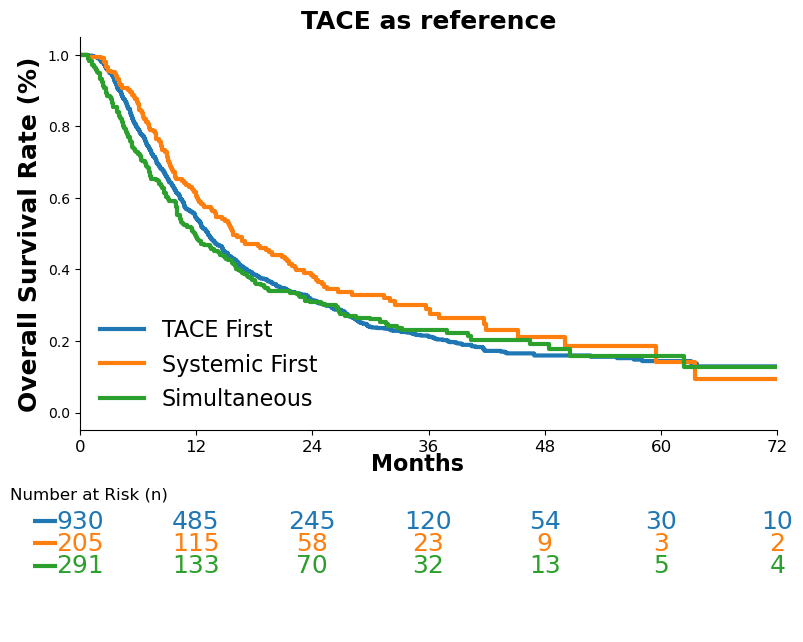

In [147]:
survival_analysis_3g(df, np.arange(0,73,12), 'sequence_group', 'TACE', 0.004)

### Systemic-ref

<lifelines.CoxPHFitter: fitted with 1426 total observations, 361 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1426
number of events observed = 1065
   partial log-likelihood = -6976.58
         time fit was run = 2025-09-29 22:39:48 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1      0.19      1.21      0.09            0.01            0.38                1.01                1.46
seq_2      0.25      1.28      0.11            0.03            0.46                1.03                1.59

           cmp to    z    p  -log2(p)
covariate                            
seq_1        0.00 2.05 0.04      4.63
seq_2        0.00 2.27 0.02      5.43
---
Concordance = 0.53
Partial AIC = 13957.16
log-likelihood ratio test = 5.76 on 2 df
-log2(p) of ll-ratio test = 4.15

Systemic First at 36 mo: 28.9% (20.6%-35.2%)
Systemic First at 60 mo: 14.0% (5.9%-25.6%)
TACE First at 36 mo: 21.3% (18.4%-24.1%)
TACE First at 60 mo: 14.4% (11.6%-17.5%)
Simultaneous at 36 mo: 23.0% (17.7%-28.6%)
Simultaneous at 60 mo: 15.8% (10.0%-22.8%)


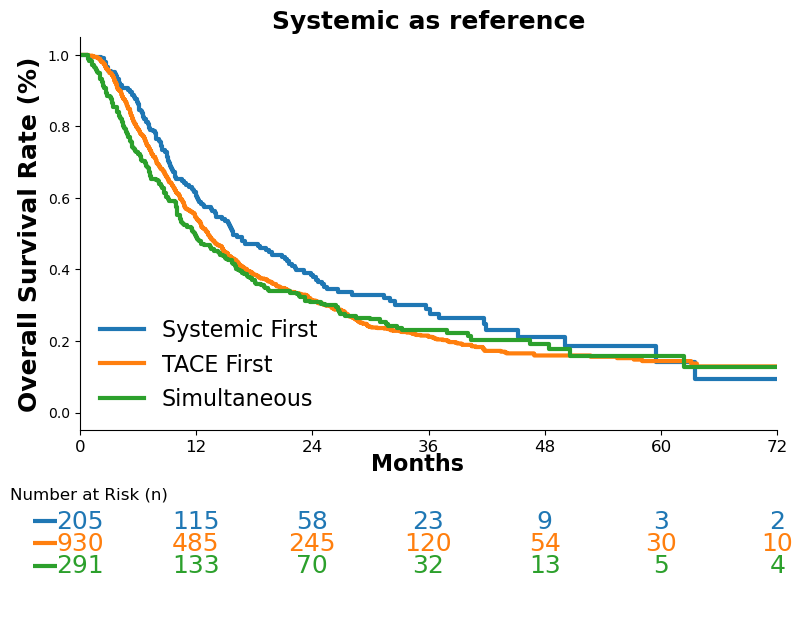

Logrank test p-value: 0.0627


In [148]:
df['sequence_group_ref_sys'] = df['sequence_group'].map({
    1: 0,   # systemic → reference level
    0: 1,   # TACE    → new level 1
    2: 2    # Simultaneous→ level 2
})
survival_analysis_3g(df, np.arange(0,73,12), 'sequence_group_ref_sys', 'Systemic', 0.004)#, file_name='3g_survival_analysis')

event_durations = np.concatenate([
    df[df['sequence_group_ref_sys'] == 0]['time'].values,
    df[df['sequence_group_ref_sys'] == 1]['time'].values,
    df[df['sequence_group_ref_sys'] == 2]['time'].values
])

groups = np.concatenate([
    np.full(len(df[df['sequence_group_ref_sys'] == 0]), 0),
    np.full(len(df[df['sequence_group_ref_sys'] == 1]), 1),
    np.full(len(df[df['sequence_group_ref_sys'] == 2]), 2)
])

event_observed = np.concatenate([
    df[df['sequence_group_ref_sys'] == 0]['event'].values,
    df[df['sequence_group_ref_sys'] == 1]['event'].values,
    df[df['sequence_group_ref_sys'] == 2]['event'].values
])

results = multivariate_logrank_test(event_durations, groups, event_observed)
print(f"Logrank test p-value: {results.p_value:.4f}")

### Simultaneous ref

<lifelines.CoxPHFitter: fitted with 1426 total observations, 361 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1426
number of events observed = 1065
   partial log-likelihood = -6976.58
         time fit was run = 2025-09-29 22:39:48 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1     -0.06      0.94      0.08           -0.21            0.10                0.81                1.10
seq_2     -0.25      0.78      0.11           -0.46           -0.03                0.63                0.97

           cmp to     z    p  -log2(p)
covariate                             
seq_1        0.00 -0.74 0.46      1.11
seq_2        0.00 -2.27 0.02      5.43
---
Concordance = 0.53
Partial AIC = 13957.16
log-likelihood ratio test = 5.76 on 2 df
-log2(p) of ll-ratio test = 4.15

Simultaneous at 36 mo: 23.0% (17.7%-28.6%)
Simultaneous at 60 mo: 15.8% (10.0%-22.8%)
TACE First at 36 mo: 21.3% (18.4%-24.1%)
TACE First at 60 mo: 14.4% (11.6%-17.5%)
Systemic First at 36 mo: 28.9% (20.6%-35.2%)
Systemic First at 60 mo: 14.0% (5.9%-25.6%)


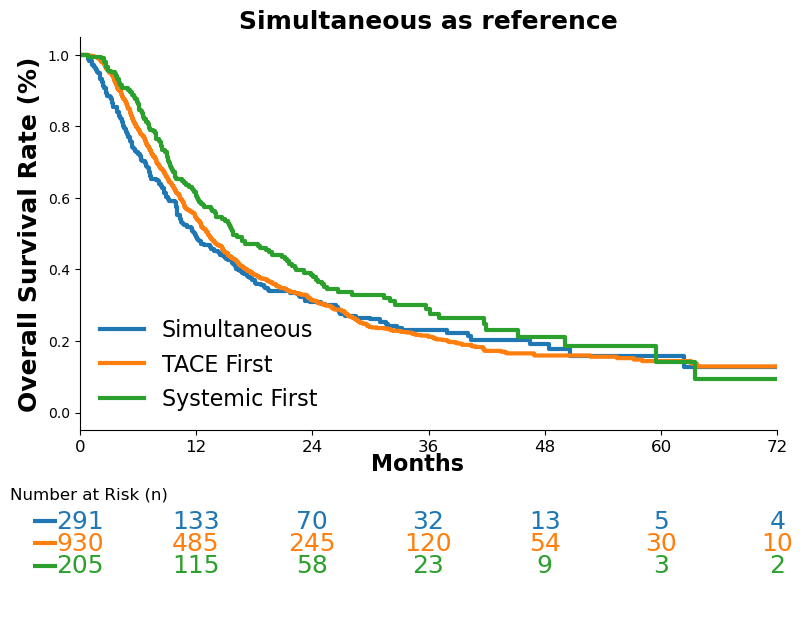

In [149]:
df['sequence_group_ref_simultaneous'] = df['sequence_group'].map({
    2: 0,   # Simultaneous → reference
    0: 1,   # TACE     → level 1
    1: 2    # systemic → level 2
})
survival_analysis_3g(df, np.arange(0,73,12), 'sequence_group_ref_simultaneous', 'Simultaneous', 0.036)

## Pairwise comparisons

### TACE vs. simultaneous

#### Subset data and Recode sequence group

In [150]:
df_TS = df[df['sequence_group'].isin([0, 2])].copy()
df_TS['sequence_group'] = df_TS['sequence_group'].map({
    0: 0,
    2: 1  # Simultaneous → new level 1
})
df_TS['sequence_group'].value_counts()

sequence_group
0    930
1    291
Name: count, dtype: int64

#### Unweighted survival analysis

<lifelines.CoxPHFitter: fitted with 1221 total observations, 292 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1221
number of events observed = 929
   partial log-likelihood = -5942.04
         time fit was run = 2025-09-29 22:39:48 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.06      1.06      0.08           -0.10            0.21                0.91                1.23

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 0.73 0.46      1.11
---
Concordance = 0.51
Partial AIC = 11886.08
log-likelihood ratio test = 0.53 on 1 df
-log2(p) of ll-ratio test = 1.10


Time: 36 months
TACE first: 21.3% (18.4% – 24.1%)
Simultaneous: 23.0% (17.7% – 28.6%)

Time: 60 months
TACE first: 14.4% (11.6% – 17.5%)
Simultaneous: 15.8% (10.0% – 22.8%)


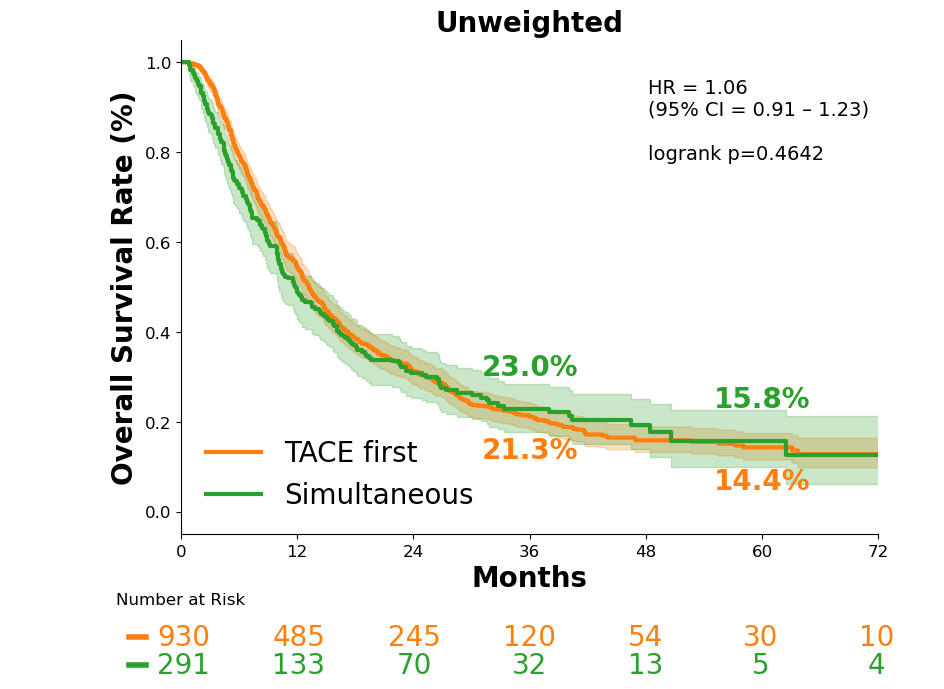

In [151]:
survival_analysis(df_TS, np.arange(0,73,12), ['TACE first', 'Simultaneous'], ['#ff7f0e','#2ca02c'])#,file_name='tace_simultaneous_unweighted')

<lifelines.CoxPHFitter: fitted with 937 total observations, 231 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 937
number of events observed = 706
   partial log-likelihood = -540.28
         time fit was run = 2025-09-29 22:39:48 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.06      1.06      0.10           -0.14            0.26                0.87                1.30

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 0.60 0.55      0.87
---
Concordance = 0.51
Partial AIC = 1082.57
log-likelihood ratio test = 0.36 on 1 df
-log2(p) of ll-ratio test = 0.87


Time: 36 months
TACE first: 21.0% (17.3% – 24.3%)
Simultaneous: 23.0% (17.7% – 28.6%)

Time: 60 months
TACE first: 15.0% (11.6% – 18.8%)
Simultaneous: 15.8% (10.0% – 22.8%)


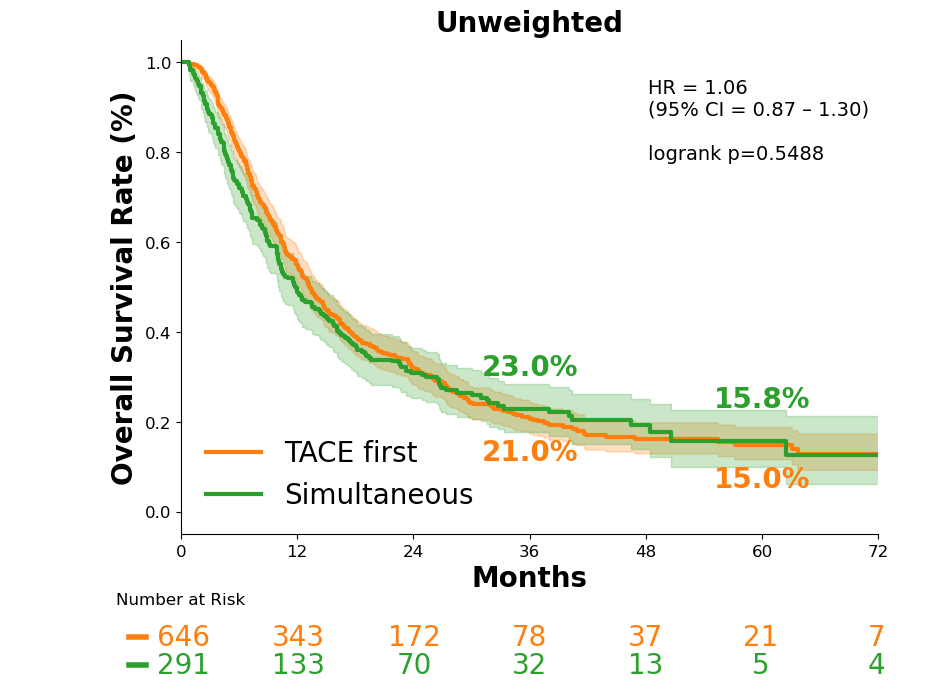

In [152]:
df_matched_tace_same = pd.read_csv('matched_tace_same.csv')
survival_analysis(df_matched_tace_same, np.arange(0,73,12), ['TACE first', 'Simultaneous'], ['#ff7f0e','#2ca02c'], strata = 'subclass')#,file_name='tace_simultaneous_unweighted')

#### IPTW

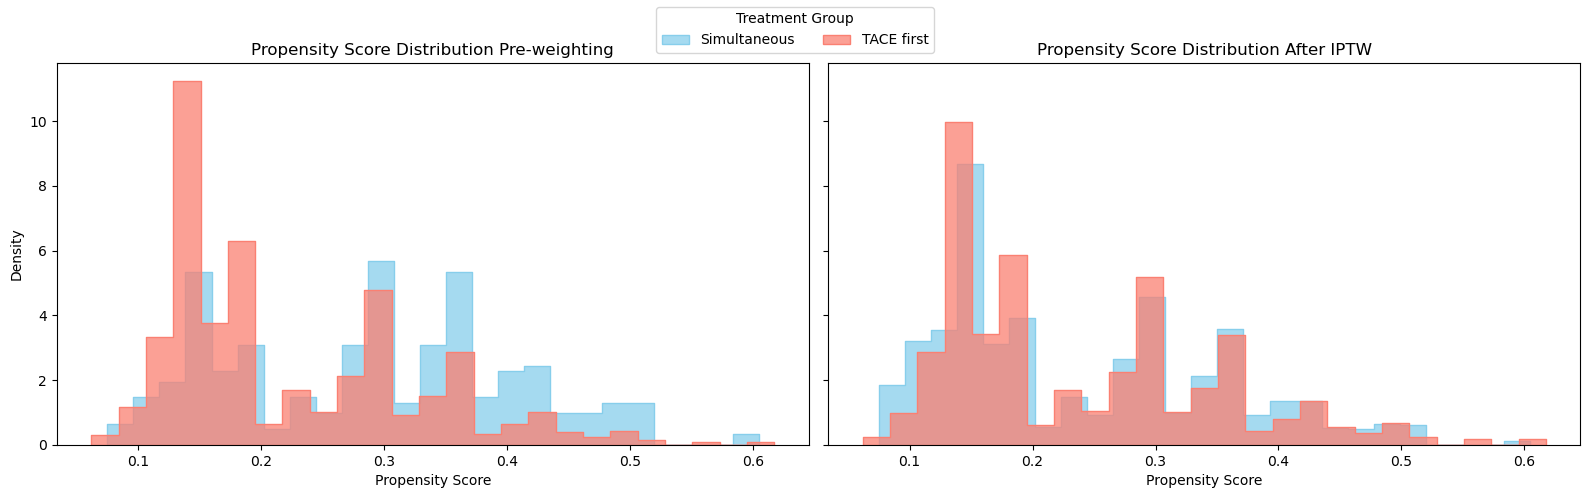

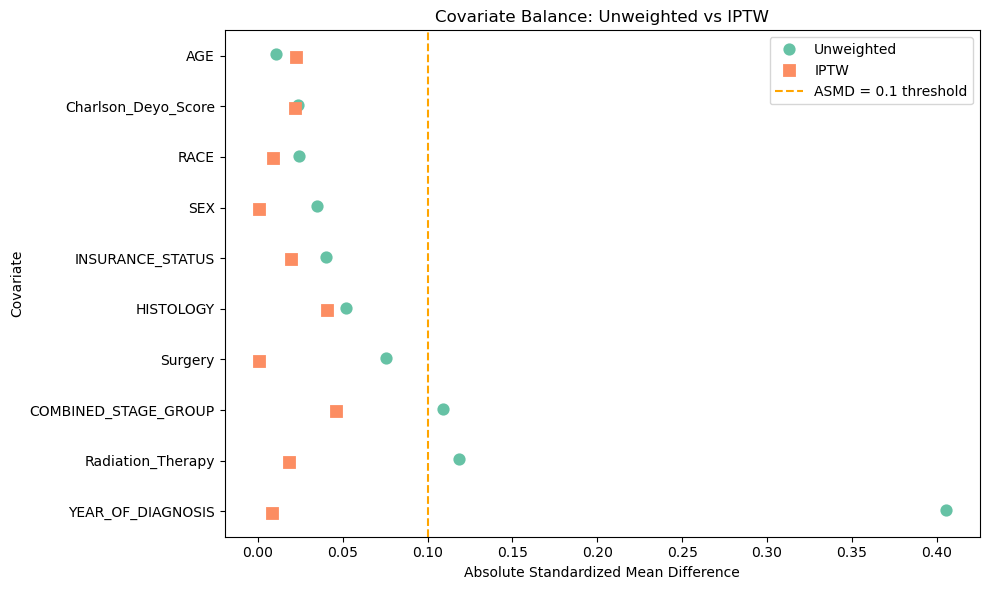

In [153]:
df_TS = perform_iptw(df_TS)
generate_iptw_plots(df_TS, ['TACE first', 'Simultaneous'])#, file_name='tace_simultaneous')

<lifelines.CoxPHFitter: fitted with 2436.79 total observations, 594.503 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2436.79
number of events observed = 1842.28
   partial log-likelihood = -13056.15
         time fit was run = 2025-09-29 22:39:50 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.01      0.99      0.05           -0.10            0.08                0.91                1.09

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -0.15 0.88      0.19
---
Concordance = 0.49
Partial AIC = 26114.30
log-likelihood ratio test = 0.02 on 1 df
-log2(p) of ll-ratio test = 0.19


Time: 36 months
TACE first: 21.0% (18.4% – 23.4%)
Simultaneous: 23.7% (21.1% – 26.3%)

Time: 60 months
TACE first: 14.3% (11.9% – 17.0%)
Simultaneous: 14.9% (11.8% – 18.4%)


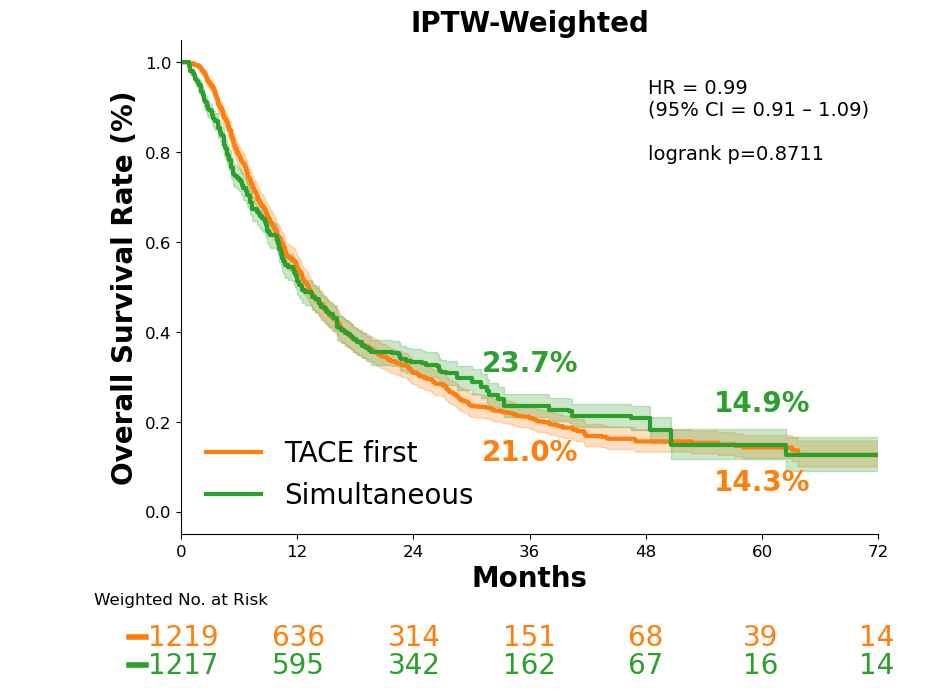

In [154]:
survival_analysis(df_TS, np.arange(0,73,12), ['TACE first', 'Simultaneous'], ['#ff7f0e','#2ca02c'], weight_col='iptw_weight')#, file_name='tace_simultaneous_iptw')

### Systemic vs. simultaneous

#### Subset data and recode sequence group

In [155]:
df_SS = df[df['sequence_group'].isin([1, 2])].copy()
df_SS['sequence_group'] = df_SS['sequence_group'].map({
    1: 1,
    2: 0  # Simultaneous → new level reference
})
df_SS['sequence_group'].value_counts()

sequence_group
0    291
1    205
Name: count, dtype: int64

#### Unweighted survival analysis

<lifelines.CoxPHFitter: fitted with 496 total observations, 145 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 496
number of events observed = 351
   partial log-likelihood = -1921.50
         time fit was run = 2025-09-29 22:39:51 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.24      0.79      0.11           -0.45           -0.02                0.64                0.98

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -2.15 0.03      5.00
---
Concordance = 0.54
Partial AIC = 3845.00
log-likelihood ratio test = 4.71 on 1 df
-log2(p) of ll-ratio test = 5.06


Time: 36 months
Simultaneous: 23.0% (17.7% – 28.6%)
Systemic first: 28.9% (20.6% – 35.2%)

Time: 60 months
Simultaneous: 15.8% (10.0% – 22.8%)
Systemic first: 14.0% (5.9% – 25.6%)


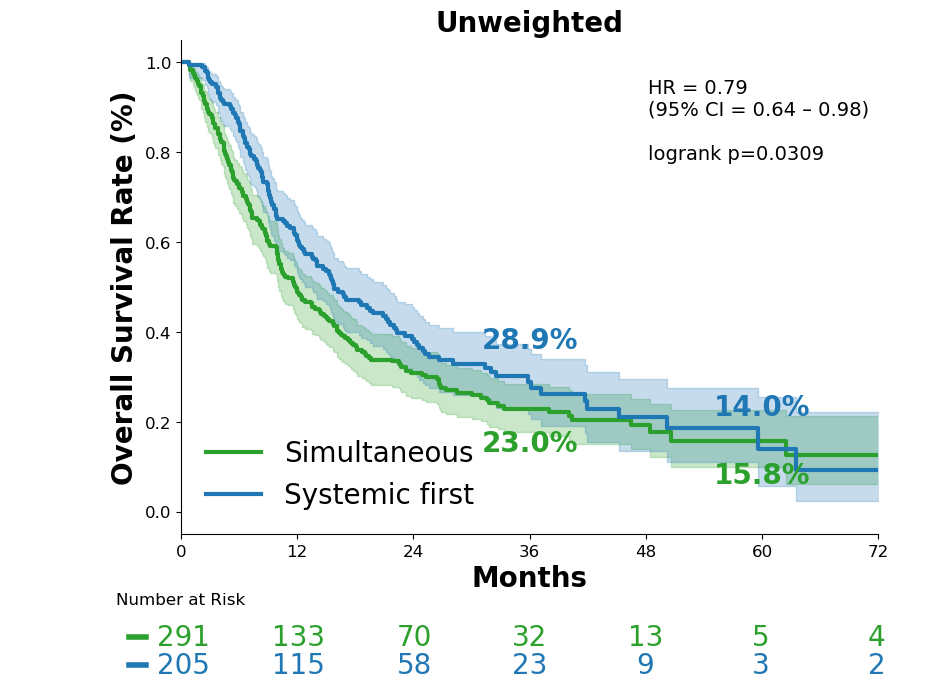

In [156]:
survival_analysis(df_SS, np.arange(0,73,12), ['Simultaneous', 'Systemic first'], colors=['#2ca02c', "#1f77b4"])#,file_name='simultaneous_sys_unweighted')

<lifelines.CoxPHFitter: fitted with 366 total observations, 118 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 366
number of events observed = 248
   partial log-likelihood = -93.39
         time fit was run = 2025-09-29 22:39:51 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.36      0.70      0.17           -0.70           -0.03                0.50                0.97

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -2.11 0.03      4.84
---
Concordance = 0.59
Partial AIC = 188.79
log-likelihood ratio test = 4.52 on 1 df
-log2(p) of ll-ratio test = 4.90


Time: 36 months
Simultaneous: 24.7% (17.9% – 32.1%)
Systemic first: 29.6% (20.9% – 36.2%)

Time: 60 months
Simultaneous: 13.7% (4.2% – 28.7%)
Systemic first: 14.3% (6.0% – 26.3%)


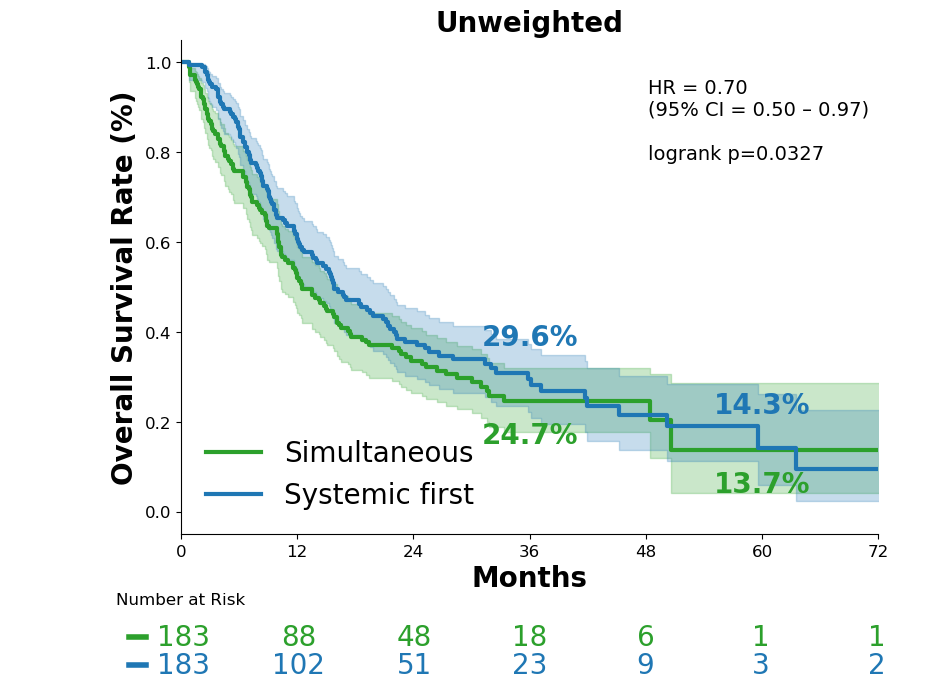

In [157]:
df_matched_same_sys = pd.read_csv('matched_same_sys.csv')
survival_analysis(df_matched_same_sys, np.arange(0,73,12), ['Simultaneous', 'Systemic first'], colors=['#2ca02c', "#1f77b4"], strata = 'subclass')#,file_name='simultaneous_sys_unweighted')

#### IPTW

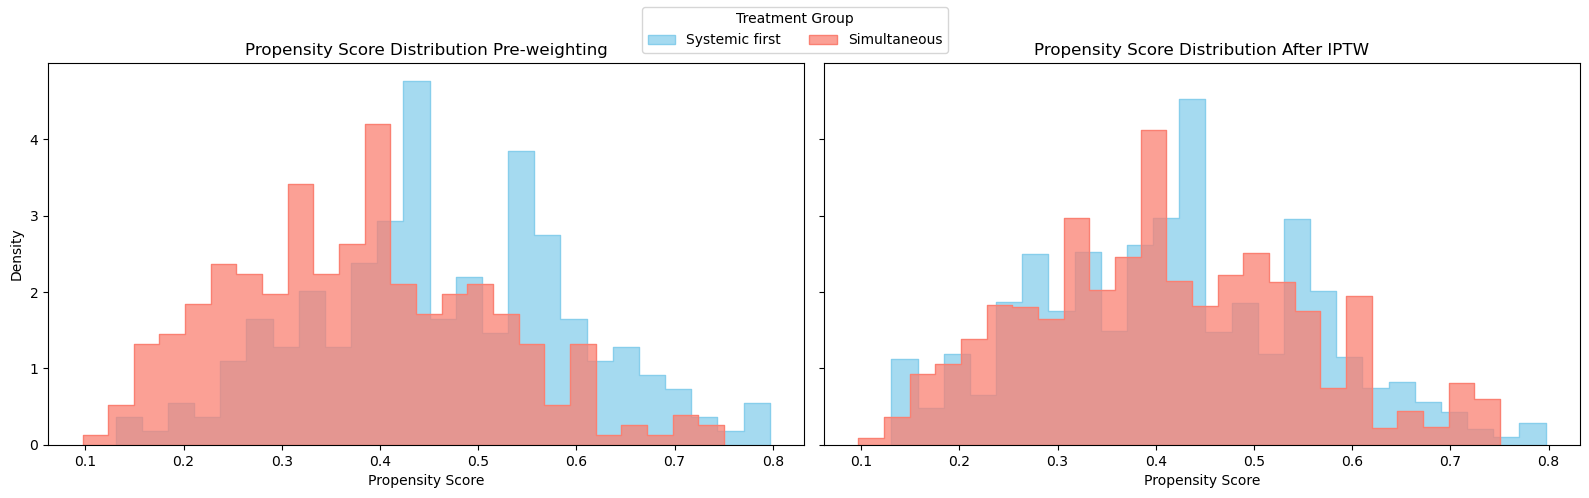

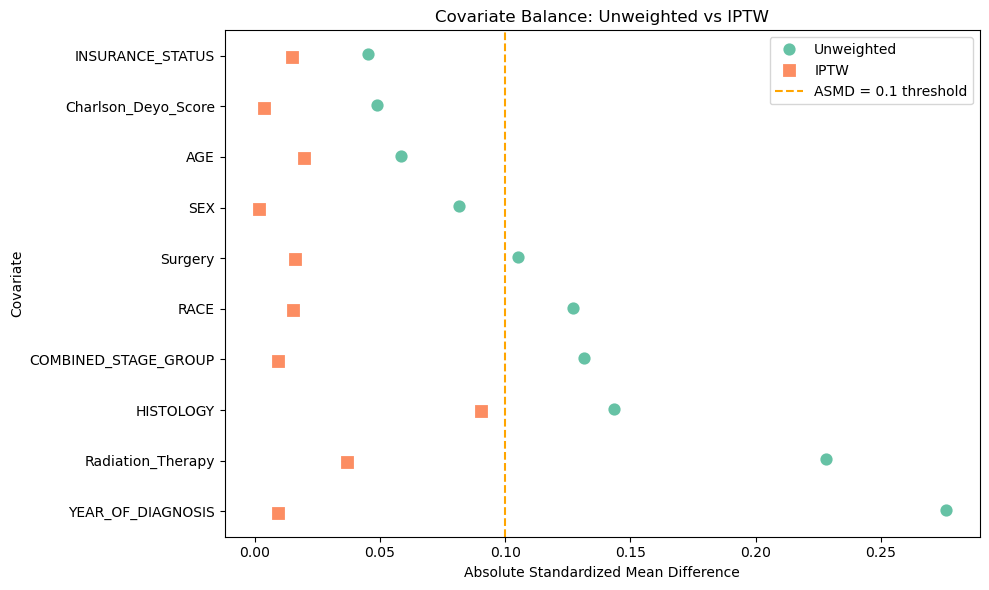

In [158]:
df_SS = perform_iptw(df_SS)
generate_iptw_plots(df_SS, ['Simultaneous', 'Systemic first'])#, file_name='simultaneous_sys')

<lifelines.CoxPHFitter: fitted with 983.813 total observations, 289.093 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 983.813
number of events observed = 694.721
   partial log-likelihood = -4268.43
         time fit was run = 2025-09-29 22:39:53 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.19      0.83      0.08           -0.34           -0.04                0.71                0.96

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -2.51 0.01      6.35
---
Concordance = 0.54
Partial AIC = 8538.87
log-likelihood ratio test = 6.27 on 1 df
-log2(p) of ll-ratio test = 6.35


Time: 36 months
Simultaneous: 24.1% (19.9% – 28.5%)
Systemic first: 29.0% (23.9% – 33.0%)

Time: 60 months
Simultaneous: 16.3% (11.0% – 22.5%)
Systemic first: 15.1% (10.4% – 20.8%)


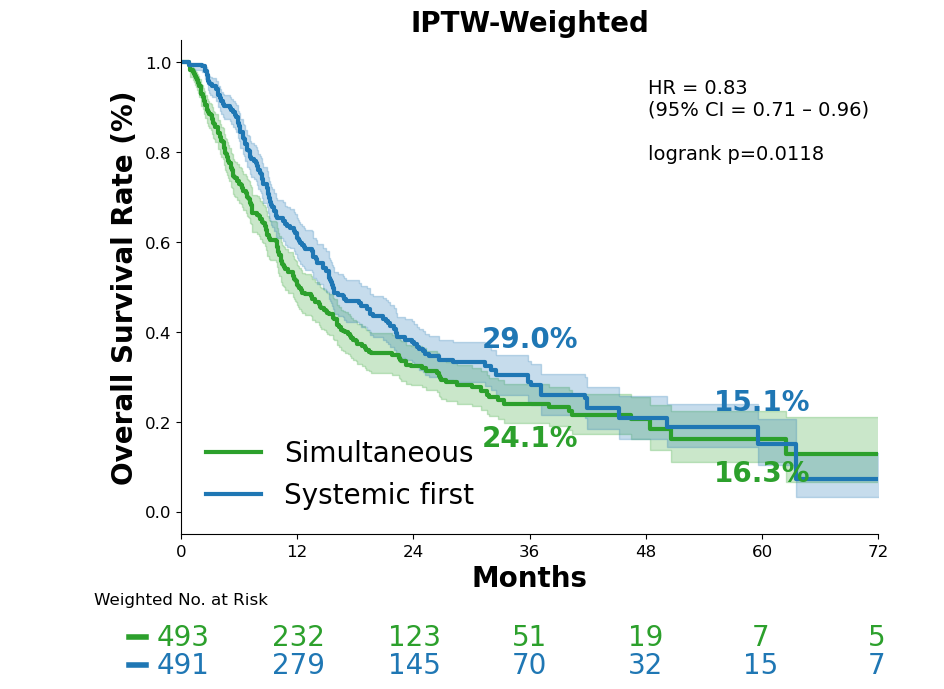

In [159]:
survival_analysis(df_SS, np.arange(0,73,12), ['Simultaneous', 'Systemic first'], colors=['#2ca02c', "#1f77b4"], weight_col='iptw_weight')#, file_name='simultaneous_sys_iptw')

In [160]:
results = logrank_test(
    df_SS[df_SS['sequence_group'] == 0]['time'],
    df_SS[df_SS['sequence_group'] == 1]['time'],
    event_observed_A=df_SS[df_SS['sequence_group'] == 0]['event'],
    event_observed_B=df_SS[df_SS['sequence_group'] == 1]['event'],
    weights_A=df_SS[df_SS['sequence_group'] == 0]['iptw_weight'],
    weights_B=df_SS[df_SS['sequence_group'] == 1]['iptw_weight']
)
print(f"Logrank p-value: {results.p_value:.4f}")

Logrank p-value: 0.0118


## Tace first vs. Simultaneous across stage combinations

In [161]:
combinations = [
    [1], [2], [3], [4],
    [1,2], [2,3], [3,4],
    [1,2,3], [2,3,4]
]

# DataFrame to store the HR and p-values for each combination
df_results = pd.DataFrame(columns=['Stage Combination', 'HR', 'CI Low', 'CI High', 'p-value', 'n'])

for combo in combinations:
    combo_name = " + ".join(map(str, combo))
    
    df_combo = pd.read_csv('analysis_ready.csv')
    df_combo = df_combo[df_combo['sequence_group'].isin([0, 2])]
    df_combo['sequence_group'] = df_combo['sequence_group'].map({
        0: 0,
        2: 1  # Simultaneous → new level 1
    })
    df_combo = df_combo[df_combo['COMBINED_STAGE_GROUP'].isin(combo)]
    if len(combo) == 1:
        covariates_1 = [cov for cov in covariates if cov != 'COMBINED_STAGE_GROUP']
        df_combo = perform_iptw(df_combo, covariates=covariates_1)
    else:
        df_combo = perform_iptw(df_combo)
    
    cph = CoxPHFitter()
    cph.fit(df_combo[['time', 'event', 'sequence_group', 'iptw_weight']], duration_col='time', event_col='event', weights_col='iptw_weight')
    
    summary_df = cph.summary
    p_val = summary_df.loc['sequence_group', 'p'].round(4)
    hr = summary_df.loc['sequence_group', 'exp(coef)']
    ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
    ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']
    
    # Create a new row as a DataFrame
    new_row = pd.DataFrame({
        'Stage Combination': [combo_name],
        'HR': [hr],
        'CI Low': [ci_low],
        'CI High': [ci_high],
        'p-value': [p_val],
        'n': [df_combo.shape[0]]
    })
    
    # Use pd.concat to add the new row
    df_results = pd.concat([df_results, new_row], ignore_index=True)

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_46107/3368829570.py:46: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_results = pd.concat([df_results, new_row], ignore_index=True)


In [162]:
df_results

,Stage Combination,HR,CI Low,CI High,p-value,n
0,1,0.832160,0.598973,1.156129,0.2734,138
1,2,1.394032,1.101683,1.763960,0.0057,215
2,3,1.004073,0.878763,1.147252,0.9523,596
3,4,1.037884,0.914752,1.177591,0.5639,625
4,1 + 2,1.089102,0.900988,1.316492,0.3776,353
5,2 + 3,1.089460,0.971196,1.222125,0.1439,811
6,3 + 4,0.992926,0.906092,1.088082,0.8792,1221
7,1 + 2 + 3,1.056923,0.948613,1.177599,0.3156,949
8,2 + 3 + 4,1.029698,0.945905,1.120913,0.4992,1436


## Simultaneous vs. Systemic first across stage combinations

In [163]:

# DataFrame to store the HR and p-values for each combination
df_results_2 = pd.DataFrame(columns=['Stage Combination', 'HR', 'CI Low', 'CI High', 'p-value', 'n'])

for combo in combinations:
    combo_name = " + ".join(map(str, combo))
    
    df_combo = pd.read_csv('analysis_ready.csv')
    df_combo = df_combo[df_combo['sequence_group'].isin([1, 2])]
    df_combo['sequence_group'] = df_combo['sequence_group'].map({
        1: 1,
        2: 0  # Simultaneous → new level reference
    })
    df_combo = df_combo[df_combo['COMBINED_STAGE_GROUP'].isin(combo)]
    
    if len(combo) == 1:
        covariates_1 = [cov for cov in covariates if cov != 'COMBINED_STAGE_GROUP']
        df_combo = perform_iptw(df_combo, covariates=covariates_1)
    else:
        df_combo = perform_iptw(df_combo)
    
    cph = CoxPHFitter()
    cph.fit(df_combo[['time', 'event', 'sequence_group', 'iptw_weight']], duration_col='time', event_col='event', weights_col='iptw_weight')
    
    summary_df = cph.summary
    p_val = summary_df.loc['sequence_group', 'p'].round(4)
    hr = summary_df.loc['sequence_group', 'exp(coef)']
    ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
    ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']
    
    # Create a new row as a DataFrame
    new_row = pd.DataFrame({
        'Stage Combination': [combo_name],
        'HR': [hr],
        'CI Low': [ci_low],
        'CI High': [ci_high],
        'p-value': [p_val],
        'n': [df_combo.shape[0]]
    })
    
    # Use pd.concat to add the new row
    df_results_2 = pd.concat([df_results_2, new_row], ignore_index=True)

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_46107/2383218541.py:41: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_results_2 = pd.concat([df_results_2, new_row], ignore_index=True)


In [164]:
df_results_2

,Stage Combination,HR,CI Low,CI High,p-value,n
0,1,1.173930,0.714595,1.928521,0.5266,72
1,2,0.876334,0.572281,1.341928,0.5437,78
2,3,0.864210,0.690078,1.082283,0.2037,235
3,4,0.698289,0.568146,0.858243,0.0006,261
4,1 + 2,0.973215,0.710624,1.332839,0.8656,150
5,2 + 3,0.867873,0.714104,1.054755,0.1544,313
6,3 + 4,0.826026,0.711316,0.959235,0.0122,496
7,1 + 2 + 3,0.927396,0.773610,1.111753,0.4152,385
8,2 + 3 + 4,0.814488,0.708355,0.936523,0.0040,574


## Table One

In [165]:
import scipy.stats as stats
import re

# Map sequence_group into three labels
group_labels = {0: "TACE First", 1: "Systemic First", 2: "Simultaneous"}
df["Group"] = df["sequence_group"].map(group_labels)

# Prepare table records
table_records = []
manual_level_order = {
    "COMBINED_STAGE_GROUP": [1, 2, 3, 4],
    "Charlson_Deyo_Score": [0, 1, 2, 3],
    "YEAR_OF_DIAGNOSIS": ["≤2017", "2018–2019", "2020+"],
    "RACE": ["White","Black","Asian","Other"],
    "Radiation_Therapy": ["Yes", "No", "Unknown"],
    
}

for col in covariates:
    p_val = ""  # initialize p-value
    
    if df[col].dtype == 'object' or df[col].nunique() <= 10:
        # Chi-square test for categorical
        contingency = pd.crosstab(df[col], df["Group"])
        if contingency.shape[0] > 1 and contingency.shape[1] > 1:
            chi2, p, _, _ = stats.chi2_contingency(contingency)
            p_val = f"{p:.4f}" if p >= 0.0001 else "<0.0001"
        
        # Determine level order
        if col in manual_level_order:
            order = manual_level_order[col]
            levels = sorted(
                df[col].dropna().unique(),
                key=lambda x: order.index(x) if x in order else float('inf')
            )
        else:
            try:
                levels = sorted(
                    df[col].dropna().unique(),
                    key=lambda x: int(re.findall(r"\d+", str(x))[0])
                                   if re.search(r"\d+", str(x))
                                   else str(x)
                )
            except:
                levels = sorted(df[col].dropna().unique())

        # Add rows per level
        for i, lvl in enumerate(levels):
            record = {}
            idx = (col, lvl)
            for grp in group_labels.values():
                mask = df['Group'] == grp
                total = mask.sum()
                count = (df.loc[mask, col] == lvl).sum()
                pct = 100 * count / total if total > 0 else 0.0
                record[grp] = f"{count} ({pct:.1f}%)"
            # ⚠️ Add p-value only to the first row of the covariate
            if i == 0:
                record["p-value"] = p_val
            else:
                record["p-value"] = ""
            table_records.append((idx, record))

    elif np.issubdtype(df[col].dtype, np.number):
        # ANOVA for continuous
        groups = [df[df["Group"] == grp][col].dropna() for grp in group_labels.values()]
        if all(len(g) > 1 for g in groups):
            _, p = stats.f_oneway(*groups)
            p_val = f"{p:.4f}" if p >= 0.0001 else "<0.0001"
        
        record = {}
        idx = (col, "mean (SD)")
        for grp in group_labels.values():
            mask = df["Group"] == grp
            mean_val = df.loc[mask, col].mean()
            sd_val = df.loc[mask, col].std()
            record[grp] = f"{mean_val:.2f} ({sd_val:.2f})"
        record["p-value"] = p_val  # ⚠️ Add p-value for continuous
        table_records.append((idx, record))

# Add "Number" row at top
number_record = {}
for grp in group_labels.values():
    total = (df["Group"] == grp).sum()
    number_record[grp] = f"{total}"
number_record["p-value"] = ""  # ⚠️ No p-value for number row
table_records.insert(0, (("Number", ""), number_record))

# Build final table
index_tuples, data = zip(*table_records)
row_index = pd.MultiIndex.from_tuples(index_tuples, names=["Covariate", "Level"])
columns = list(group_labels.values()) + ["p-value"]
formatted_table = pd.DataFrame(list(data), index=row_index, columns=columns)

# Reorder covariates if needed
manual_covariate_order = [
    "Number", "AGE", "SEX", "RACE",
    "COMBINED_STAGE_GROUP", "Charlson_Deyo_Score",
    "YEAR_OF_DIAGNOSIS", "HISTOLOGY", "Radiation_Therapy", "Surgery", "INSURANCE_STATUS"
]
new_index = []
for cov in manual_covariate_order:
    new_index.extend([idx for idx in formatted_table.index if idx[0] == cov])
formatted_table = formatted_table.loc[new_index]

# Output table
formatted_table


TACE First Systemic First  \
Covariate            Level                                                
Number                                               930            205   
AGE                  mean (SD)             64.28 (10.44)  63.74 (10.84)   
SEX                  Female                  182 (19.6%)     44 (21.5%)   
                     Male                    748 (80.4%)    161 (78.5%)   
RACE                 White                   664 (71.4%)    123 (60.0%)   
                     Black                   148 (15.9%)     36 (17.6%)   
                     Asian                     88 (9.5%)     37 (18.0%)   
                     Other                     30 (3.2%)       9 (4.4%)   
COMBINED_STAGE_GROUP 3                       466 (50.1%)    105 (51.2%)   
                     4                       464 (49.9%)    100 (48.8%)   
Charlson_Deyo_Score  0                       484 (52.0%)    105 (51.2%)   
                     1                       212 (22.8%)     62 (30.2%)   
                     2                       117 (12.6%)      16 (7.8%)   
                     3                       117 (12.6%)     22 (10.7%)   
YEAR_OF_DIAGNOSIS    2020+                   304 (32.7%)    131 (63.9%)   
                     2017–2019               552 (59.4%)     57 (27.8%)   
                     ≤2016                     74 (8.0%)      17 (8.3%)   
HISTOLOGY            Clear cell HCC             5 (0.5%)       4 (2.0%)   
                     HCC, NOS                922 (99.1%)    200 (97.6%)   
                     Scirrhous HCC              2 (0.2%)       0 (0.0%)   
                     Spindle cell HCC           1 (0.1%)       1 (0.5%)   
Radiation_Therapy    Yes                     260 (28.0%)     71 (34.6%)   
                     No                      661 (71.1%)    133 (64.9%)   
                     Unknown                    9 (1.0%)       1 (0.5%)   
Surgery              No                      869 (93.4%)    190 (92.7%)   
                     Yes                       61 (6.6%)      15 (7.3%)   
INSURANCE_STATUS     Medicaid                139 (14.9%)     33 (16.1%)   
                     Medicare                455 (48.9%)     98 (47.8%)   
                     No insurance              32 (3.4%)       6 (2.9%)   
                     Other Government          17 (1.8%)       3 (1.5%)   
                     Private/Managed Care    273 (29.4%)     62 (30.2%)   
                     Unknown                   14 (1.5%)       3 (1.5%)   

                                            Simultaneous  p-value  
Covariate            Level                                         
Number                                               291           
AGE                  mean (SD)             64.40 (11.71)   0.7734  
SEX                  Female                   53 (18.2%)   0.6678  
                     Male                    238 (81.8%)           
RACE                 White                   204 (70.1%)   0.0132  
                     Black                    46 (15.8%)           
                     Asian                    29 (10.0%)           
                     Other                     12 (4.1%)           
COMBINED_STAGE_GROUP 3                       130 (44.7%)   0.2203  
                     4                       161 (55.3%)           
Charlson_Deyo_Score  0                       161 (55.3%)   0.0585  
                     1                        61 (21.0%)           
                     2                         26 (8.9%)           
                     3                        43 (14.8%)           
YEAR_OF_DIAGNOSIS    2020+                   135 (46.4%)  <0.0001  
                     2017–2019                95 (32.6%)           
                     ≤2016                    61 (21.0%)           
HISTOLOGY            Clear cell HCC             1 (0.3%)   0.1838  
                     HCC, NOS                290 (99.7%)           
                     Scirrhous HCC              0 (0.0%)           

In [166]:
# import xlsxwriter

# # Set output file path
# output_path = "3group_Table1_3days_0926.xlsx"
# workbook = xlsxwriter.Workbook(output_path)
# worksheet = workbook.add_worksheet("Table 1")

# # Define formats
# bold_center = workbook.add_format({'bold': True, 'align': 'center', 'valign': 'vcenter'})
# bold_left   = workbook.add_format({'bold': True, 'align': 'left',   'valign': 'vcenter'})
# center      = workbook.add_format({'align': 'center','valign': 'vcenter'})
# gray_fill   = workbook.add_format({'bg_color': '#f2f2f2', 'align': 'center','valign':'vcenter'})
# gray_bold   = workbook.add_format({'bg_color': '#f2f2f2','bold':True,'align':'left','valign':'vcenter'})

# # Write title
# worksheet.write(0, 0, "Table 1. Baseline Characteristics", bold_left)

# # Header row
# worksheet.write(1, 0, "Characteristic", bold_center)
# worksheet.write(1, 1, "Level",          bold_center)
# for j, col_name in enumerate(formatted_table.columns, start=2):
#     worksheet.write(1, j, col_name, bold_center)

# # Start writing data at row 2
# row_start = 2
# row_blocks = {}  # collect row indices by covariate

# # Write each row of formatted_table
# for i, ((cov, lvl), row_vals) in enumerate(formatted_table.iterrows()):
#     r = row_start + i
#     worksheet.write(r, 1, lvl, center)  # Level

#     for j, val in enumerate(row_vals, start=2):  # Data columns incl. p-value
#         worksheet.write(r, j, val, center)

#     row_blocks.setdefault(cov, []).append(r)

# # Merge & style 'Characteristic' column + alternate shading
# for idx, (cov, rows) in enumerate(row_blocks.items()):
#     header_fmt = gray_bold if idx % 2 == 0 else bold_left
#     cell_fmt   = gray_fill if idx % 2 == 0 else center

#     # Merge or single cell
#     if len(rows) == 1:
#         worksheet.write(rows[0], 0, cov, header_fmt)
#     else:
#         worksheet.merge_range(rows[0], 0, rows[-1], 0, cov, header_fmt)

#     # Shade the Level and Data cells
#     for r in rows:
#         worksheet.write(r, 1, formatted_table.index[r - row_start][1], cell_fmt)
#         for c in range(2, 2 + len(formatted_table.columns)):
#             val = formatted_table.iloc[r - row_start, c - 2]
#             worksheet.write(r, c, val, cell_fmt)

# # Adjust column widths
# worksheet.set_column(0, 0, 30)  # Characteristic
# worksheet.set_column(1, 1, 20)  # Level
# for c in range(2, 2 + len(formatted_table.columns)):
#     worksheet.set_column(c, c, 22)  # Data columns including p-value

# workbook.close()
# print(f"✅ Saved formatted Excel file to: {output_path}")
